# NB-IoT-Style Demodulation

Edit **Editable settings**, then use **Run All** or execute cells from top to bottom. Metrics and plots appear directly below the code. Set `capture` to a complex64 `.bin` or `.npy` file to analyze a recording.

This example uses the generic NR core with a 1-RB QPSK configuration; it is not a complete standards-specific NB-IoT receiver.

In [1]:
%matplotlib inline
import os
from pathlib import Path

if os.name == "nt":
    packages = Path(os.environ["LOCALAPPDATA"]) / "Microsoft" / "WinGet" / "Packages"
    for runtime_dir in packages.glob("BrechtSanders.WinLibs.POSIX.UCRT_*/mingw64/bin"):
        os.environ["PATH"] = str(runtime_dir) + os.pathsep + os.environ.get("PATH", "")


## Imports

In [2]:
"""NB-IoT-style 1-RB QPSK scratch experiment using the generic NR core."""

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

example_dir = Path(globals().get("__file__", Path.cwd() / "iot_demod_pyscratch.py")).resolve().parent
for package_dir in (example_dir.parent, Path.cwd() / "nrdemod" / "python", Path.cwd() / "python", Path.cwd()):
    if (package_dir / "nrdemod" / "__init__.py").is_file():
        sys.path.insert(0, str(package_dir))
        break

import nrdemod


## Editable settings

In [3]:
capture = None
sample_rate = 1.92e6
carrier_offset = 0.0
cfo_hz = 200.0
snr_db = 35.0
num_symbols = 14
seed = 7


## Configure demodulator

In [4]:
cfg = nrdemod.Config(
    numerology=0,
    frequencyRange=nrdemod.FR1,
    channelBandwidthMHz=0,
    numResourceBlocks=1,
    resourceBlockOffset=0,
    transformPrecoding=False,
    resample=True,
    burstSearch=False,
    sampleRate=sample_rate,
    modulation=nrdemod.QPSK,
    carrierOffsetHz=carrier_offset,
)


## Generate or load I/Q

In [5]:
if capture is None:
    generation_cfg = nrdemod.Config(**{**cfg.__dict__, "carrierOffsetHz": 0.0})
    ideal_iq = nrdemod.generate_test_signal(generation_cfg, num_symbols=num_symbols, leading_samples=64, seed=seed)
    rng = np.random.default_rng(3)
    shifted_iq = ideal_iq.astype(np.complex128) * np.exp(2j * np.pi * cfo_hz * np.arange(ideal_iq.size) / sample_rate)
    noise_sigma = np.sqrt(np.mean(np.abs(shifted_iq) ** 2)) * 10 ** (-snr_db / 20) / np.sqrt(2)
    noise = noise_sigma * (rng.standard_normal(ideal_iq.size) + 1j * rng.standard_normal(ideal_iq.size))
    iq = (shifted_iq + noise).astype(np.complex64)
else:
    capture_path = Path(capture)
    iq = np.load(capture_path).astype(np.complex64) if capture_path.suffix.lower() == ".npy" else np.fromfile(capture_path, dtype=np.complex64)
if iq.ndim != 1 or iq.size == 0:
    raise ValueError("Expected a nonempty one-dimensional complex I/Q capture")
print(f"{iq.size} samples at {sample_rate / 1e6:g} MS/s")


1984 samples at 1.92 MS/s


## Plot input I/Q

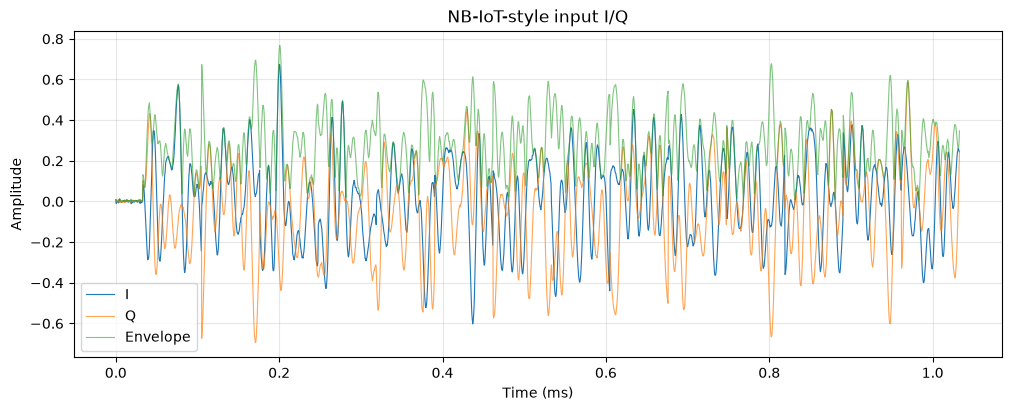

In [6]:
time_ms = np.arange(iq.size) / sample_rate * 1e3
waveform_figure, waveform_axis = plt.subplots(figsize=(10, 4), constrained_layout=True)
waveform_axis.plot(time_ms, iq.real, label="I", linewidth=0.8)
waveform_axis.plot(time_ms, iq.imag, label="Q", linewidth=0.8, alpha=0.7)
waveform_axis.plot(time_ms, np.abs(iq), label="Envelope", linewidth=0.8, alpha=0.6)
waveform_axis.set(title="NB-IoT-style input I/Q", xlabel="Time (ms)", ylabel="Amplitude")
waveform_axis.legend()
waveform_axis.grid(True, alpha=0.3)
plt.show()


## Plot input spectrum

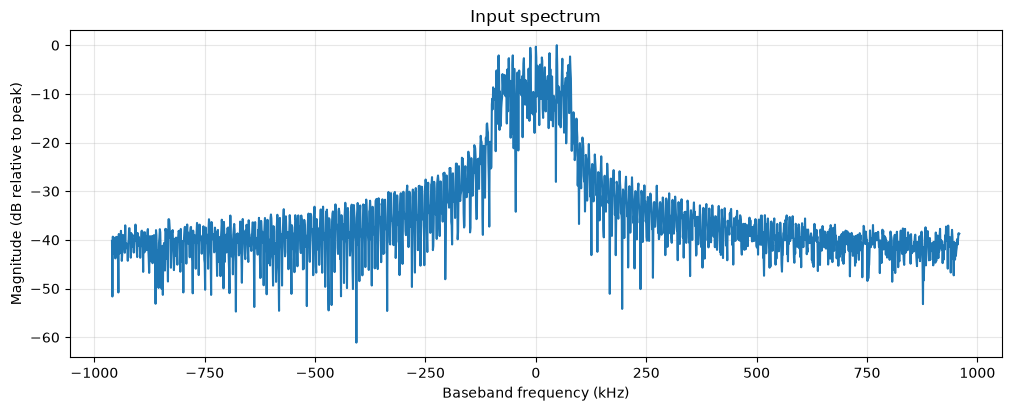

In [7]:
frequency_khz = np.fft.fftshift(np.fft.fftfreq(iq.size, d=1 / sample_rate)) / 1e3
spectrum = np.abs(np.fft.fftshift(np.fft.fft(iq * np.hanning(iq.size))))
spectrum_db = 20 * np.log10(np.maximum(spectrum / max(float(spectrum.max()), 1e-12), 1e-12))
spectrum_figure, spectrum_axis = plt.subplots(figsize=(10, 4), constrained_layout=True)
spectrum_axis.plot(frequency_khz, spectrum_db)
spectrum_axis.set(title="Input spectrum", xlabel="Baseband frequency (kHz)", ylabel="Magnitude (dB relative to peak)")
spectrum_axis.grid(True, alpha=0.3)
plt.show()


## Demodulate and inspect metrics

In [ ]:
settings = vars(cfg).copy()
sample_rate = settings.pop("sampleRate")
res = nrdemod.demodulate_nbiot(iq, sample_rate, **settings)
if not res.ok:
    raise RuntimeError(f"Demodulation failed: {res.error}")
metrics = res.as_dict()
print(f"RMS EVM: {res.rmsEvmPercent:.3f}%")
print(f"Peak EVM: {res.peakEvmPercent:.3f}%")
print(f"Frequency error: {res.frequencyErrorHz:.1f} Hz")
print(f"Modulation: {res.modulation_name}, symbols: {res.numSymbols}")

RMS EVM: 0.514%
Peak EVM: 1.320%
Frequency error: 200.1 Hz
Modulation: QPSK, symbols: 14


## Plot demodulated constellation

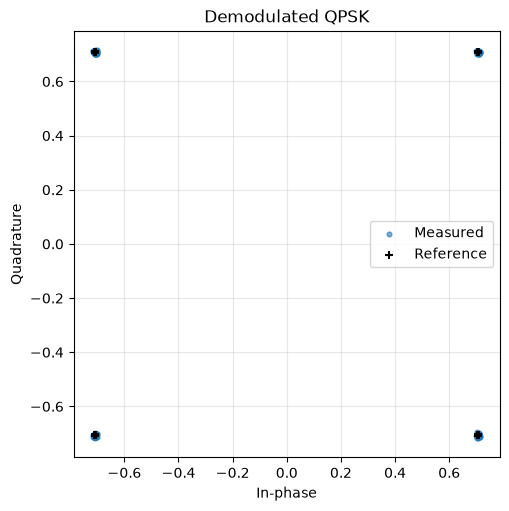

In [9]:
constellation_figure, constellation_axis = plt.subplots(figsize=(5, 5), constrained_layout=True)
constellation_axis.scatter(res.constellation.real, res.constellation.imag, s=12, alpha=0.6, label="Measured")
constellation_axis.scatter(res.reference.real, res.reference.imag, s=40, marker="+", color="black", label="Reference")
constellation_axis.set(title="Demodulated QPSK", xlabel="In-phase", ylabel="Quadrature")
constellation_axis.set_aspect("equal", adjustable="box")
constellation_axis.legend()
constellation_axis.grid(True, alpha=0.3)
plt.show()


## Plot EVM per symbol

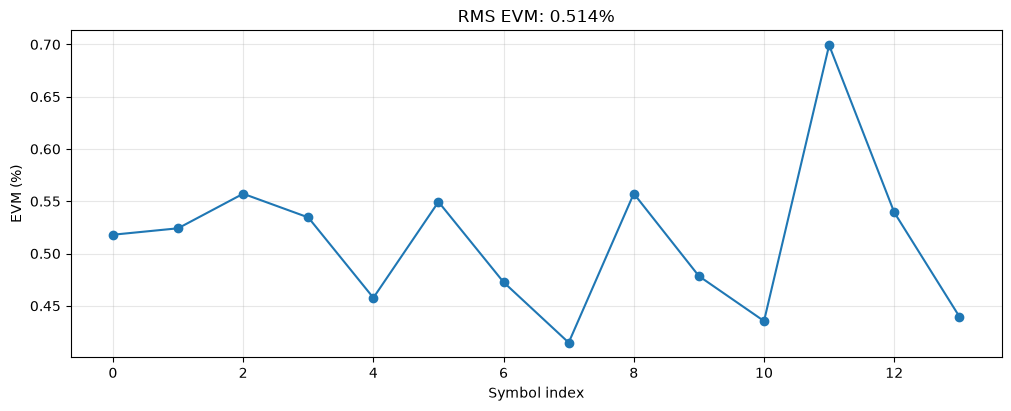

In [10]:
evm_figure, evm_axis = plt.subplots(figsize=(10, 4), constrained_layout=True)
evm_axis.plot(np.arange(res.evmPerSymbol.size), res.evmPerSymbol, marker="o")
evm_axis.set(title=f"RMS EVM: {res.rmsEvmPercent:.3f}%", xlabel="Symbol index", ylabel="EVM (%)")
evm_axis.grid(True, alpha=0.3)
plt.show()
